In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pybaselines import Baseline
from astropy.convolution import Gaussian1DKernel
from spanks.synthetic_spectra import get_synthetic_spectrum
from spanks.noise_suppressor1D import suppress_noise1d

# 1. Making the spectrum for the test

# 1.1 Get a synthetic spectrum
lambda_range = (3000, 8000)
number_of_lines = 15
delta_lambda = 2
dynamic_range = (0.25, 4)
which_lines = "both"
fwhm_range = (10, 70)
noise_std = 0.25
continuum_amplitude = 2
continuum_alpha = -1.3
break_amplitude = 2
break_grow_rate = 0.03
break_lambda = 3700
clean_peaks = False
np.random.seed(42) # Change to generate a different spectrum
spec_x, spec_y, lines_loc = get_synthetic_spectrum(lambda_range, delta_lambda, number_of_lines, which_lines, fwhm_range, dynamic_range, noise_std,
                                                   continuum_amplitude, continuum_alpha, break_amplitude, break_grow_rate, break_lambda, clean_peaks)

# 1.2 Add custom test lines to the spectrum
test_line_locs = [5400, 5000, 6500]
test_line_scales = [15.0,20.0,10.0]
test_line_amplitudes = [0.7,0.5,0.9]
for test_line_pars in zip(test_line_locs, test_line_scales, test_line_amplitudes):
    test_line = stats.norm.pdf(spec_x, loc=test_line_pars[0], scale=test_line_pars[1])
    test_line = test_line_pars[2] * test_line/test_line.max()
    spec_y += test_line

# Uncomment: optionally smooth data to improve SNR but loose some resolution
# from spanks.utils import smoothen_data
# spec_x = smoothen_data(spec_x, 2)
# spec_y = smoothen_data(spec_y, 2)


In [5]:
# 2. Suppressing noise
# 2.1 Estimate continuum for temporary subtraction
baseline_fitter = Baseline(x_data=spec_x)
bkg, params  = baseline_fitter.mixture_model(spec_y, lam=1e2, p=0.5, symmetric=True, num_knots = 150, spline_degree=3)

# 2.2 Applying different noise suppression methods
sup_kernel = Gaussian1DKernel(2.0).array.copy()
y_simple = suppress_noise1d(spec_y - bkg, method="simple", kernel = sup_kernel) + bkg
y_logit = suppress_noise1d(spec_y - bkg, method="logit", kernel = sup_kernel) + bkg
y_layers = suppress_noise1d(spec_y - bkg, method="layers", kernel = sup_kernel) + bkg

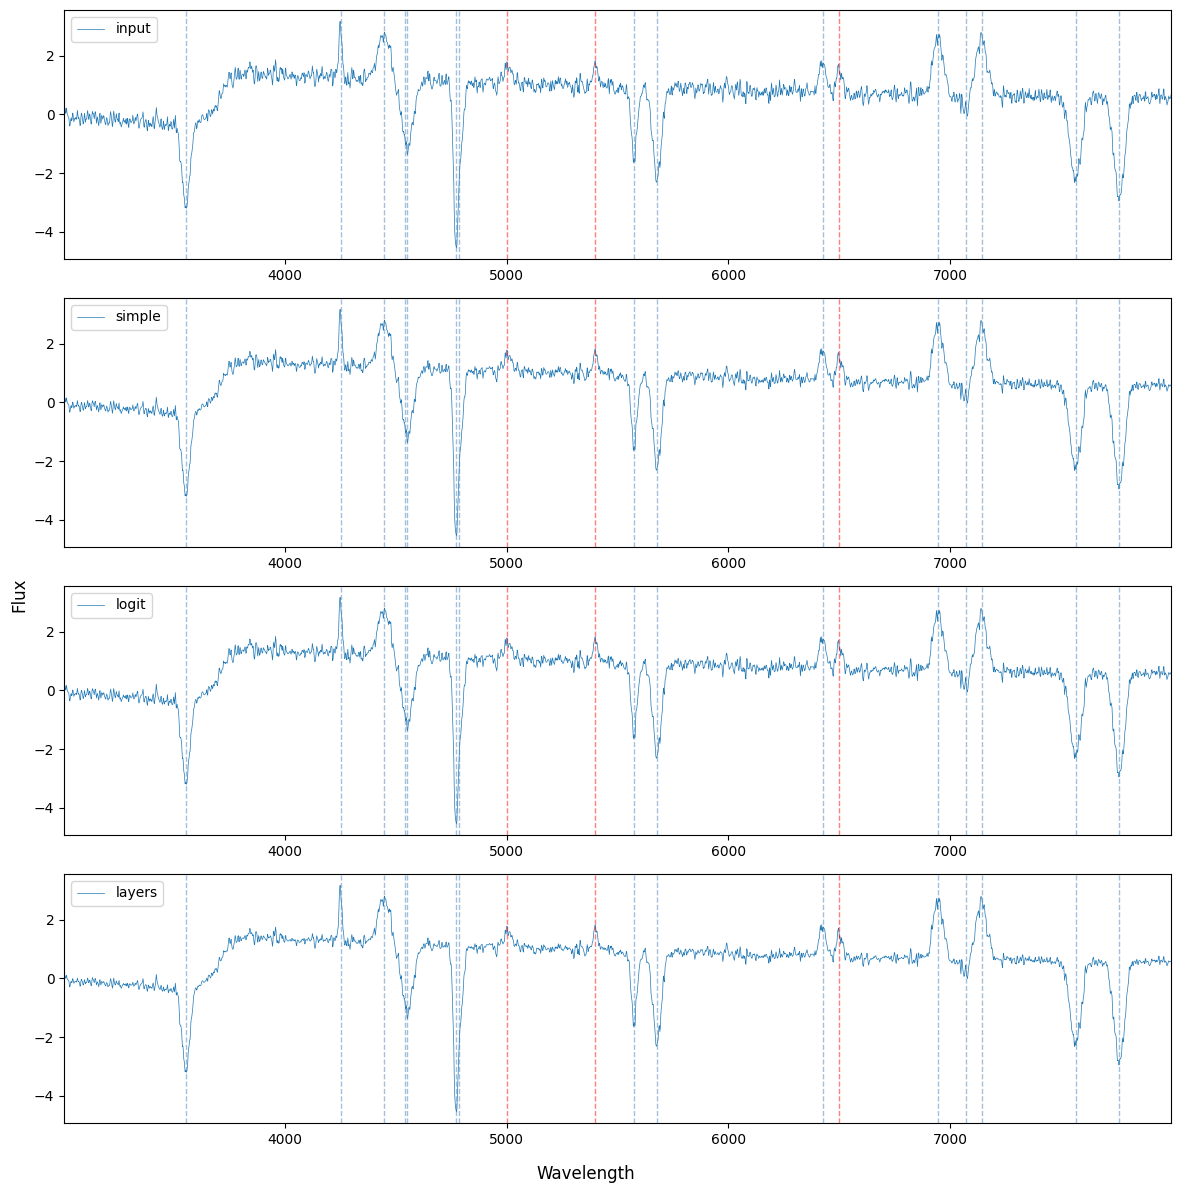

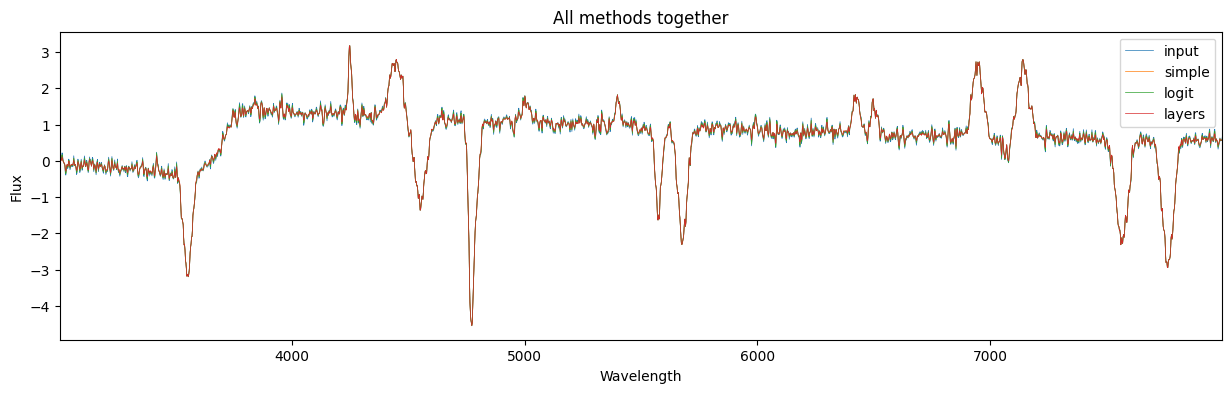

In [6]:

# 3. Plotting results
y_methods = [spec_y, y_simple, y_logit, y_layers]
y_labels = ["input","simple", "logit", "layers"]

# 3.1 Comparing all methods separately
linew = 0.5
figsize = (12,12)
fig, ax = plt.subplots(4,1, figsize = figsize)
for ax_i, y_method in enumerate(zip(y_methods, y_labels)):
    ax[ax_i].plot(spec_x, y_method[0], lw = linew, label = y_method[1])
    # Default lines in blue
    for line_pos in lines_loc:
        ax[ax_i].axvline(line_pos, ls = "--", lw = 1.0, alpha = 0.5, color = "steelblue")
    # Custom test lines in red
    for line_pos in test_line_locs:
        ax[ax_i].axvline(line_pos, ls = "--", lw = 1.0, alpha = 0.5, color = "red")
    ax[ax_i].set_xlim(spec_x[0], spec_x[-1])
    ax[ax_i].legend()
fig.supxlabel("Wavelength")
fig.supylabel("Flux")
plt.tight_layout()
plt.show()

# 3.2 Comparing all methods together
fig = plt.figure(figsize = (15,4))
plt.title("All methods together")
for y_method in zip(y_methods, y_labels):
    plt.plot(spec_x, y_method[0], lw = linew, label = y_method[1])
plt.legend()
plt.xlim(spec_x[0], spec_x[-1])
plt.xlabel("Wavelength")
plt.ylabel("Flux")
plt.show()

